# Donut Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

A pie chart with the center removed. Readers judge arc length rather than angle, and the hole holds a headline number such as the total or the key share. The same limits as a pie apply.

## When to use

- Show a part-to-whole split with few categories (≤ 6) and a headline figure
- Dashboards where a single compact share indicator is needed

## Avoid when

- There are more than 6 segments, or the segments are close in size
- Precise comparison is needed (use a bar chart)

## Alternatives

- Pie chart
- Stacked bar (single bar)
- Stat tile with the number only

## Design tips

- Put the key number in the center hole
- Keep the ring thick enough (~30% of the radius) to read the arcs

## Example

Repayment status of a consumer loan book of 1,240 loans.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
s = pd.Series({"Current": 1050, "30–89 days late": 112, "90+ days late": 48, "Defaulted": 30})
s

Current            1050
30–89 days late     112
90+ days late        48
Defaulted            30
dtype: int64

### Plot

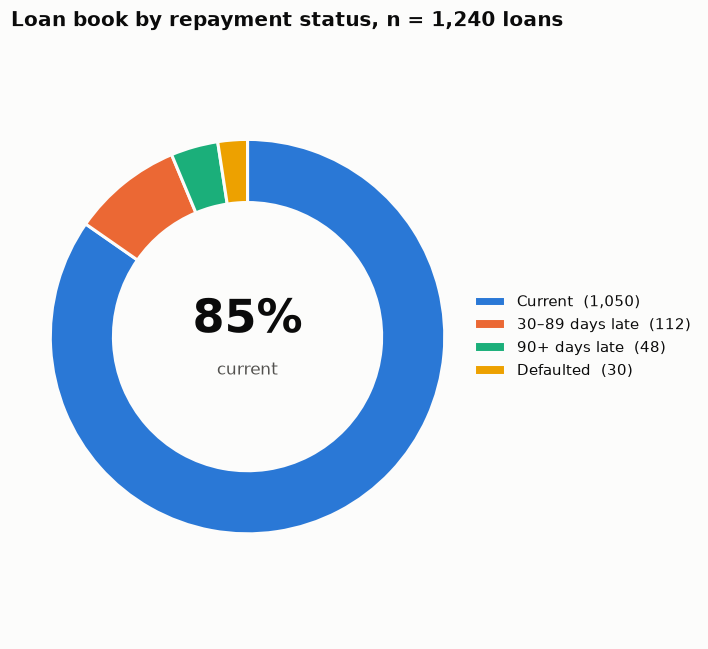

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
wedges, _ = ax.pie(s.values, colors=PALETTE[:len(s)], startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.32, edgecolor="#fcfcfb", linewidth=2))
ax.text(0, 0.08, f"{s['Current'] / s.sum():.0%}", ha="center", va="center",
        fontsize=30, fontweight="bold")
ax.text(0, -0.17, "current", ha="center", va="center", fontsize=11, color="#52514e")
ax.legend(wedges, [f"{k}  ({v:,})" for k, v in s.items()], loc="center left",
          bbox_to_anchor=(0.95, 0.5))
ax.set_title(f"Loan book by repayment status, n = {s.sum():,} loans")
ax.axis("equal")
fig.tight_layout()
plt.show()

---
Standalone script: [`donut_chart.py`](donut_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)